# TikTok: Claims Classification Data (Regression Modeling Stage)

Case study from the Google Advanced Data Analytics Professional Certificate (Course 4: Regression Analysis). Building a logistic regression model to predict whether a video's author is verified, as input to the future claims classification model.

# **Build a regression model**

## Plan

### Imports and data loading

In [75]:
# Import packages for data manipulation
import pandas as pd
import numpy as np

# Import packages for data visualization
import matplotlib.pyplot as plt
import seaborn as sns


# Import packages for data preprocessing
from sklearn.preprocessing import OneHotEncoder
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.utils import resample



# Import packages for data modeling
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


In [76]:
# Load dataset into dataframe
data = pd.read_csv("tiktok_dataset.csv")

## Analyze

### Data exploration

In [77]:
# Display first few rows
data.head()

,#,claim_status,video_id,video_duration_sec,video_transcription_text,verified_status,author_ban_status,video_view_count,video_like_count,video_share_count,video_download_count,video_comment_count
0,1,claim,7017666017,59,someone shared with me that drone deliveries a...,not verified,under review,343296.0,19425.0,241.0,1.0,0.0
1,2,claim,4014381136,32,someone shared with me that there are more mic...,not verified,active,140877.0,77355.0,19034.0,1161.0,684.0
2,3,claim,9859838091,31,someone shared with me that american industria...,not verified,active,902185.0,97690.0,2858.0,833.0,329.0
3,4,claim,1866847991,25,someone shared with me that the metro of st. p...,not verified,active,437506.0,239954.0,34812.0,1234.0,584.0
4,5,claim,7105231098,19,someone shared with me that the number of busi...,not verified,active,56167.0,34987.0,4110.0,547.0,152.0


In [78]:
# Get number of rows and columns
data.shape


(19382, 12)

In [79]:
# Get data types of columns
data.dtypes


#                             int64
claim_status                 object
video_id                      int64
video_duration_sec            int64
video_transcription_text     object
verified_status              object
author_ban_status            object
video_view_count            float64
video_like_count            float64
video_share_count           float64
video_download_count        float64
video_comment_count         float64
dtype: object

In [80]:
# Get basic information
data.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19382 entries, 0 to 19381
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   #                         19382 non-null  int64  
 1   claim_status              19084 non-null  object 
 2   video_id                  19382 non-null  int64  
 3   video_duration_sec        19382 non-null  int64  
 4   video_transcription_text  19084 non-null  object 
 5   verified_status           19382 non-null  object 
 6   author_ban_status         19382 non-null  object 
 7   video_view_count          19084 non-null  float64
 8   video_like_count          19084 non-null  float64
 9   video_share_count         19084 non-null  float64
 10  video_download_count      19084 non-null  float64
 11  video_comment_count       19084 non-null  float64
dtypes: float64(5), int64(3), object(4)
memory usage: 1.8+ MB


In [81]:
# Generate basic descriptive stats
data.describe()


,#,video_id,video_duration_sec,video_view_count,video_like_count,video_share_count,video_download_count,video_comment_count
count,19382.000000,1.938200e+04,19382.000000,19084.000000,19084.000000,19084.000000,19084.000000,19084.000000
mean,9691.500000,5.627454e+09,32.421732,254708.558688,84304.636030,16735.248323,1049.429627,349.312146
std,5595.245794,2.536440e+09,16.229967,322893.280814,133420.546814,32036.174350,2004.299894,799.638865
min,1.000000,1.234959e+09,5.000000,20.000000,0.000000,0.000000,0.000000,0.000000
25%,4846.250000,3.430417e+09,18.000000,4942.500000,810.750000,115.000000,7.000000,1.000000
50%,9691.500000,5.618664e+09,32.000000,9954.500000,3403.500000,717.000000,46.000000,9.000000
75%,14536.750000,7.843960e+09,47.000000,504327.000000,125020.000000,18222.000000,1156.250000,292.000000
max,19382.000000,9.999873e+09,60.000000,999817.000000,657830.000000,256130.000000,14994.000000,9599.000000


Check for and handle missing values.

In [82]:
# Check for missing values
data.isna().sum()

#                             0
claim_status                298
video_id                      0
video_duration_sec            0
video_transcription_text    298
verified_status               0
author_ban_status             0
video_view_count            298
video_like_count            298
video_share_count           298
video_download_count        298
video_comment_count         298
dtype: int64

In [83]:
# Drop rows with missing values
data = data.dropna(axis=0)

In [84]:
# Display first few rows after handling missing values
data.head()

,#,claim_status,video_id,video_duration_sec,video_transcription_text,verified_status,author_ban_status,video_view_count,video_like_count,video_share_count,video_download_count,video_comment_count
0,1,claim,7017666017,59,someone shared with me that drone deliveries a...,not verified,under review,343296.0,19425.0,241.0,1.0,0.0
1,2,claim,4014381136,32,someone shared with me that there are more mic...,not verified,active,140877.0,77355.0,19034.0,1161.0,684.0
2,3,claim,9859838091,31,someone shared with me that american industria...,not verified,active,902185.0,97690.0,2858.0,833.0,329.0
3,4,claim,1866847991,25,someone shared with me that the metro of st. p...,not verified,active,437506.0,239954.0,34812.0,1234.0,584.0
4,5,claim,7105231098,19,someone shared with me that the number of busi...,not verified,active,56167.0,34987.0,4110.0,547.0,152.0


Check for and handle duplicates.

In [85]:
# Check for duplicates
data.duplicated().sum()

0

Check for and handle outliers.

<Axes: >

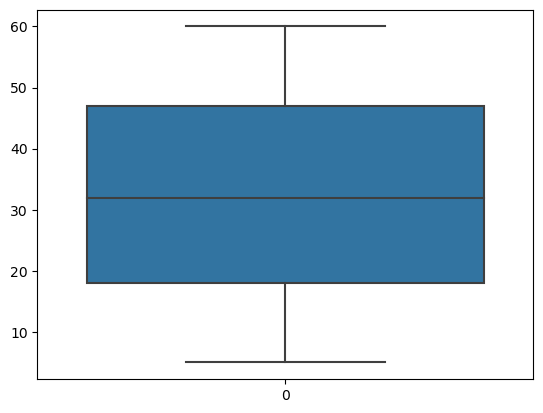

In [86]:
# Create a boxplot to visualize distribution of `video_duration_sec`
sns.boxplot(data["video_duration_sec"])



<Axes: >

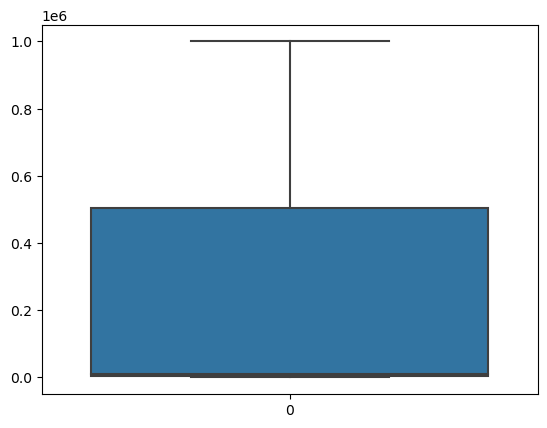

In [87]:
# Create a boxplot to visualize distribution of `video_view_count`
sns.boxplot(data["video_view_count"])



<Axes: >

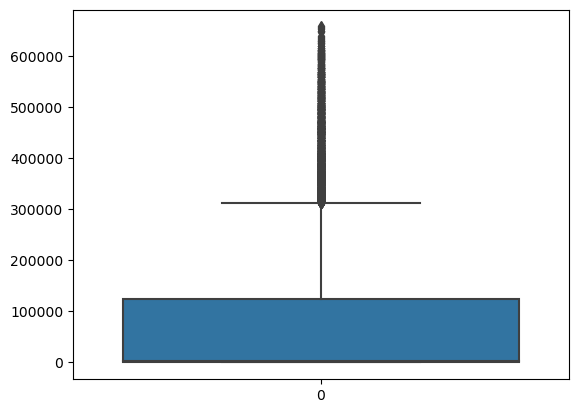

In [88]:
# Create a boxplot to visualize distribution of `video_like_count`
sns.boxplot(data["video_like_count"])



<Axes: >

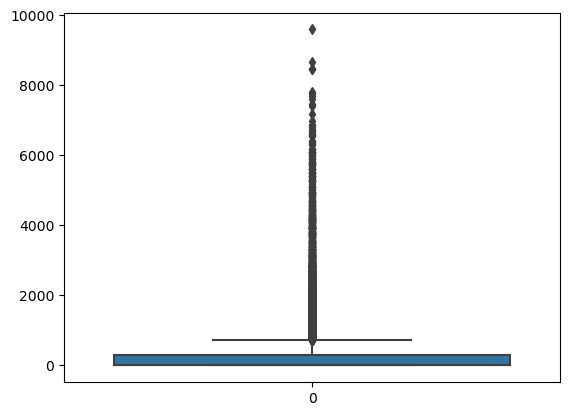

In [89]:
# Create a boxplot to visualize distribution of `video_comment_count`
sns.boxplot(data["video_comment_count"])



In [90]:
# Check for and handle outliers for video_like_count
q1 = data["video_like_count"].quantile(0.25)
q3 = data["video_like_count"].quantile(0.75)

iqr = q3 -q1

upper = q3 + 1.5 * iqr

data["video_like_count"] = data["video_like_count"].apply(lambda x: upper if x > upper else x)


Check class balance of the target variable. The goal is to predict whether the user of a given post is verified or unverified.

In [91]:
# Check class balance
data["verified_status"].value_counts(normalize =True)


verified_status
not verified    0.93712
verified        0.06288
Name: proportion, dtype: float64

Approximately 93.7% of the dataset represents videos posted by unverified accounts and 6.3% represents videos posted by verified accounts. So the outcome variable is not very balanced.

In [92]:
# Use resampling to create class balance in the outcome variable, if needed
# Identify data points from majority and minority classes
major = data[data["verified_status"] == "not verified"]
minor = data[data["verified_status"] == "verified"]

# Upsample the minority class (which is "verified")
minor_upsample = resample(minor, replace = True, n_samples = len(major), random_state = 0) 

# Combine majority class with upsampled minority class
combined_data = pd.concat([major, minor_upsample]).reset_index(drop=True)

# Display new class counts
combined_data["verified_status"].value_counts()

verified_status
not verified    17884
verified        17884
Name: count, dtype: int64

In [93]:
# Get the average `video_transcription_text` length for claims and the average `video_transcription_text` length for opinions
combined_data.groupby("verified_status")["video_transcription_text"].apply(lambda x: x.str.len().mean())

verified_status
not verified    89.401141
verified        84.569559
Name: video_transcription_text, dtype: float64

In [94]:
# Extract the length of each `video_transcription_text` and add this as a column to the dataframe
combined_data["txt_length"] = combined_data["video_transcription_text"].str.len()


In [95]:
# Display first few rows of dataframe after adding new column
combined_data.head()


,#,claim_status,video_id,video_duration_sec,video_transcription_text,verified_status,author_ban_status,video_view_count,video_like_count,video_share_count,video_download_count,video_comment_count,txt_length
0,1,claim,7017666017,59,someone shared with me that drone deliveries a...,not verified,under review,343296.0,19425.0,241.0,1.0,0.0,97
1,2,claim,4014381136,32,someone shared with me that there are more mic...,not verified,active,140877.0,77355.0,19034.0,1161.0,684.0,107
2,3,claim,9859838091,31,someone shared with me that american industria...,not verified,active,902185.0,97690.0,2858.0,833.0,329.0,137
3,4,claim,1866847991,25,someone shared with me that the metro of st. p...,not verified,active,437506.0,239954.0,34812.0,1234.0,584.0,131
4,5,claim,7105231098,19,someone shared with me that the number of busi...,not verified,active,56167.0,34987.0,4110.0,547.0,152.0,128


/opt/conda/lib/python3.11/site-packages/seaborn/axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


<Figure size 700x600 with 0 Axes>

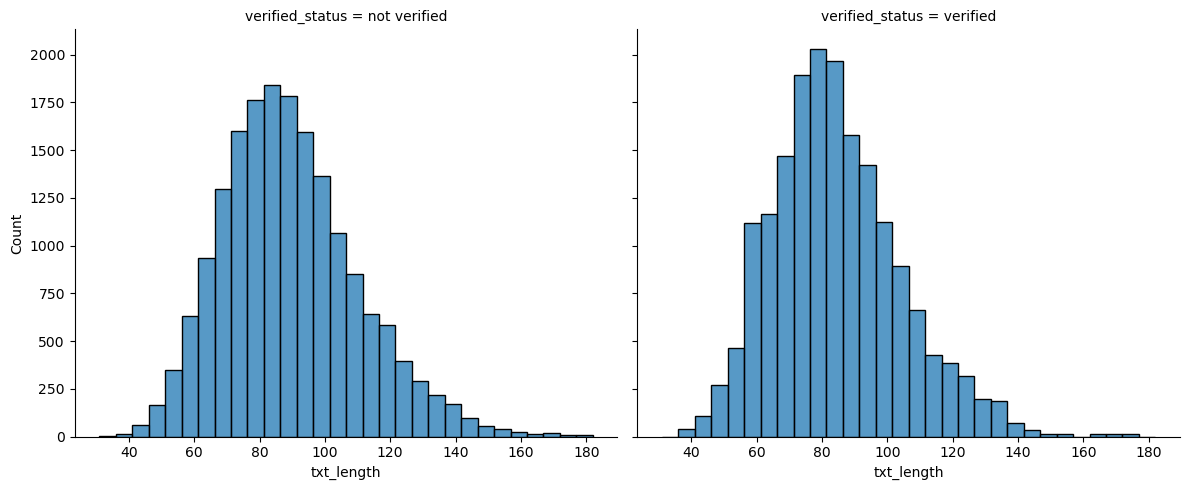

In [96]:
# Visualize the distribution of `video_transcription_text` length for videos posted by verified accounts and videos posted by unverified accounts
# Create two histograms in one plot
plt.figure(figsize=(7, 6))
sns.displot(data=combined_data, x="txt_length", col="verified_status",
            bins=30, height=5, aspect=1.2)

### Examine correlations

In [97]:
# Code a correlation matrix to help determine most correlated variables
combined_data.corr(numeric_only=True)


,#,video_id,video_duration_sec,video_view_count,video_like_count,video_share_count,video_download_count,video_comment_count,txt_length
#,1.000000,-0.000853,-0.011729,-0.697007,-0.626385,-0.504015,-0.487096,-0.413799,-0.193677
video_id,-0.000853,1.000000,0.011859,0.002554,0.005993,0.010515,0.008753,0.013983,-0.007083
video_duration_sec,-0.011729,0.011859,1.000000,0.013589,0.004494,0.002206,0.003989,-0.004586,-0.002981
video_view_count,-0.697007,0.002554,0.013589,1.000000,0.856937,0.711313,0.690048,0.583485,0.244693
video_like_count,-0.626385,0.005993,0.004494,0.856937,1.000000,0.832146,0.805543,0.686647,0.216693
video_share_count,-0.504015,0.010515,0.002206,0.711313,0.832146,1.000000,0.710117,0.620182,0.171651
video_download_count,-0.487096,0.008753,0.003989,0.690048,0.805543,0.710117,1.000000,0.857679,0.173396
video_comment_count,-0.413799,0.013983,-0.004586,0.583485,0.686647,0.620182,0.857679,1.000000,0.149750
txt_length,-0.193677,-0.007083,-0.002981,0.244693,0.216693,0.171651,0.173396,0.149750,1.000000


<Axes: >

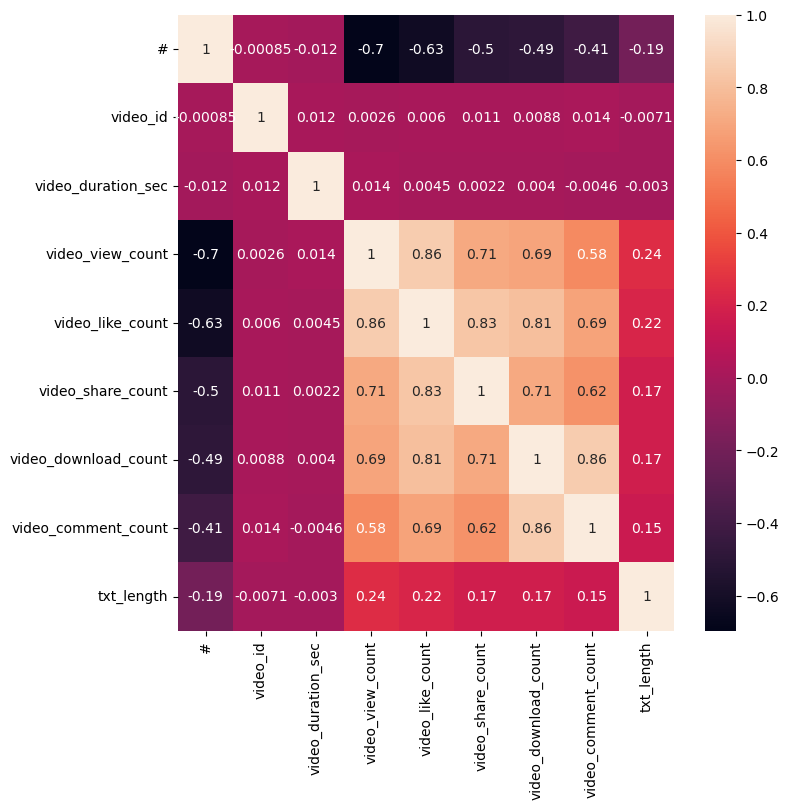

In [98]:
# Create a heatmap to visualize how correlated variables are
plt.figure(figsize=(8,8))
sns.heatmap(combined_data.corr(numeric_only=True), annot=True)


One of the model assumptions for logistic regression is no severe multicollinearity among the features. This is taken into consideration when examining the heatmap and choosing which features to proceed with.

## Construct

### Select variables

In [99]:
# Select outcome variable
y = combined_data["verified_status"]


In [100]:
# Select features
x = combined_data[["video_duration_sec", "claim_status", "author_ban_status","video_view_count", "video_share_count","video_comment_count"]]


# Display first few rows of features dataframe
x.head()


,video_duration_sec,claim_status,author_ban_status,video_view_count,video_share_count,video_comment_count
0,59,claim,under review,343296.0,241.0,0.0
1,32,claim,active,140877.0,19034.0,684.0
2,31,claim,active,902185.0,2858.0,329.0
3,25,claim,active,437506.0,34812.0,584.0
4,19,claim,active,56167.0,4110.0,152.0


### Train-test split

In [101]:
# Split the data into training and testing sets
x_train, x_test, y_train, y_test = train_test_split(x,y, test_size=0.30, random_state=7) 


In [102]:
# Get shape of each training and testing set
x_train.shape , x_test.shape, y_train.shape, y_test.shape


((25037, 6), (10731, 6), (25037,), (10731,))

### Encode variables

In [103]:
# Check data types
x_train.dtypes


video_duration_sec       int64
claim_status            object
author_ban_status       object
video_view_count       float64
video_share_count      float64
video_comment_count    float64
dtype: object

In [104]:
# Get unique values in `claim_status`
x_train["claim_status"].unique()



array(['claim', 'opinion'], dtype=object)

In [105]:
# Get unique values in `author_ban_status`
x_train["author_ban_status"].unique()


array(['under review', 'active', 'banned'], dtype=object)

As shown above, the `claim_status` and `author_ban_status` features are each of data type `object` currently. In order to work with the implementations of models through `sklearn`, these categorical features will need to be made numeric. One way to do this is through one-hot encoding.

In [106]:
# Select the training features that needs to be encoded
encode_features = x_train[["claim_status", "author_ban_status"]]

# Display first few rows
encode_features.head()


,claim_status,author_ban_status
3477,claim,under review
26049,opinion,active
10118,opinion,active
5947,claim,active
12761,opinion,active


In [107]:
# Set up an encoder for one-hot encoding the categorical features
encoder = OneHotEncoder(drop="first", sparse_output = False)


In [108]:
# Fit and transform the training features using the encoder
encoded_features = encoder.fit_transform(encode_features)


In [109]:
# Get feature names from encoder
encoder.get_feature_names_out()

array(['claim_status_opinion', 'author_ban_status_banned',
       'author_ban_status_under review'], dtype=object)

In [110]:
# Display first few rows of encoded training features
encoded_features

array([[0., 0., 1.],
       [1., 0., 0.],
       [1., 0., 0.],
       ...,
       [1., 0., 0.],
       [0., 0., 0.],
       [1., 0., 0.]])

In [111]:
# Place encoded training features (which is currently an array) into a dataframe
encoded_df = pd.DataFrame(data = encoded_features, columns = encoder.get_feature_names_out())


# Display first few rows
encoded_df.head()


,claim_status_opinion,author_ban_status_banned,author_ban_status_under review
0,0.0,0.0,1.0
1,1.0,0.0,0.0
2,1.0,0.0,0.0
3,0.0,0.0,0.0
4,1.0,0.0,0.0


In [112]:
# Display first few rows of `X_train` with `claim_status` and `author_ban_status` columns dropped (since these features are being transformed to numeric)
x_train = x_train.drop(columns=["claim_status","author_ban_status"]).reset_index(drop=True)
x_train.head()

,video_duration_sec,video_view_count,video_share_count,video_comment_count
0,27,755435.0,32197.0,271.0
1,31,4436.0,151.0,15.0
2,34,1539.0,84.0,0.0
3,38,103687.0,2609.0,9.0
4,46,3615.0,5.0,4.0


In [113]:
# Concatenate `X_train` and `X_train_encoded_df` to form the final dataframe for training data (`X_train_final`)
# Note: Using `.reset_index(drop=True)` to reset the index in X_train after dropping `claim_status` and `author_ban_status`,
# so that the indices align with those in `X_train_encoded_df` and `count_df`
x_train_final = pd.concat([x_train,encoded_df], axis=1)
# Display first few rows
x_train_final.head()

,video_duration_sec,video_view_count,video_share_count,video_comment_count,claim_status_opinion,author_ban_status_banned,author_ban_status_under review
0,27,755435.0,32197.0,271.0,0.0,0.0,1.0
1,31,4436.0,151.0,15.0,1.0,0.0,0.0
2,34,1539.0,84.0,0.0,1.0,0.0,0.0
3,38,103687.0,2609.0,9.0,0.0,0.0,0.0
4,46,3615.0,5.0,4.0,1.0,0.0,0.0


In [114]:
# Check data type of outcome variable
y_train.dtype


dtype('O')

In [115]:
# Get unique values of outcome variable
y_train.unique()


array(['not verified', 'verified'], dtype=object)

As shown above, the outcome variable is of data type `object` currently. One-hot encoding can be used to make this variable numeric.

In [116]:
# Set up an encoder for one-hot encoding the categorical outcome variable
encode = OneHotEncoder(drop="first" , sparse_output = False)


In [117]:
# Encode the training outcome variable
# Notes:
#   - Adjusting the shape of `y_train` before passing into `.fit_transform()`, since it takes in 2D array
#   - Using `.ravel()` to flatten the array returned by `.fit_transform()`, so that it can be used later to train the model
encoded_y = encode.fit_transform(y_train.values.reshape(-1, 1))
encoded_outcome = encoded_y.ravel()
# Display the encoded training outcome variable
encoded_outcome
# why not just do mapping? why all that?

array([0., 1., 0., ..., 0., 0., 0.])

### Model building

In [118]:
# Construct a logistic regression model and fit it to the training set
lr_model = LogisticRegression().fit(x_train_final,encoded_outcome)



## Execute

### Results and evaluation

In [119]:
# Select the testing features that needs to be encoded
# Transform the testing features using the encoder
# Display first few rows of encoded testing features

encoded_test = encoder.transform(x_test[["claim_status", "author_ban_status"]])

encoded_test


array([[1., 0., 0.],
       [1., 0., 0.],
       [0., 0., 0.],
       ...,
       [1., 0., 0.],
       [0., 0., 0.],
       [1., 0., 0.]])

In [120]:
# Place encoded testing features (which is currently an array) into a dataframe
x_test_last = pd.DataFrame(data = encoded_test, columns = encoder.get_feature_names_out())


# Display first few rows
x_test_last.head()


,claim_status_opinion,author_ban_status_banned,author_ban_status_under review
0,1.0,0.0,0.0
1,1.0,0.0,0.0
2,0.0,0.0,0.0
3,0.0,0.0,1.0
4,0.0,0.0,0.0


In [121]:
# Display first few rows of `X_test` with `claim_status` and `author_ban_status` columns dropped (since these features are being transformed to numeric)
x_test = x_test.drop(columns=["claim_status","author_ban_status"]).reset_index(drop=True)
x_test.head()

,video_duration_sec,video_view_count,video_share_count,video_comment_count
0,9,2559.0,229.0,1.0
1,37,8041.0,18.0,1.0
2,57,564025.0,18578.0,639.0
3,26,576728.0,33381.0,915.0
4,22,533380.0,11787.0,30.0


In [122]:
# Concatenate `X_test` and `X_test_encoded_df` to form the final dataframe for training data (`X_test_final`)
# Note: Using `.reset_index(drop=True)` to reset the index in X_test after dropping `claim_status`, and `author_ban_status`,
# so that the indices align with those in `X_test_encoded_df` and `test_count_df`
x_test_final = pd.concat([x_test,x_test_last], axis=1)


# Display first few rows
x_test_final


,video_duration_sec,video_view_count,video_share_count,video_comment_count,claim_status_opinion,author_ban_status_banned,author_ban_status_under review
0,9,2559.0,229.0,1.0,1.0,0.0,0.0
1,37,8041.0,18.0,1.0,1.0,0.0,0.0
2,57,564025.0,18578.0,639.0,0.0,0.0,0.0
3,26,576728.0,33381.0,915.0,0.0,0.0,1.0
4,22,533380.0,11787.0,30.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...
10726,17,4458.0,111.0,2.0,1.0,1.0,0.0
10727,7,9572.0,539.0,7.0,1.0,0.0,0.0
10728,44,9353.0,31.0,0.0,1.0,0.0,0.0
10729,24,244746.0,2944.0,62.0,0.0,0.0,0.0


In [123]:
# Use the logistic regression model to get predictions on the encoded testing set
y_pred = lr_model.predict(x_test_final)


In [124]:
# Display the predictions on the encoded testing set
y_pred


array([1., 1., 0., ..., 1., 0., 1.])

In [125]:
# Display the true labels of the testing set
y_test


14328    not verified
14584    not verified
3957     not verified
8041     not verified
6159     not verified
             ...     
18067        verified
33673        verified
25060        verified
176      not verified
21821        verified
Name: verified_status, Length: 10731, dtype: object

In [131]:
# Encode the testing outcome variable
# Notes:
#   - Adjusting the shape of `y_test` before passing into `.transform()`, since it takes in 2D array
#   - Using `.ravel()` to flatten the array returned by `.transform()`, so that it can be used later to compare with predictions
y_test_encode = encode.transform(y_test.values.reshape(-1, 1))
encoded_y_test = y_test_encode.ravel()

# Display the encoded testing outcome variable
encoded_y_test

array([0., 0., 0., ..., 1., 0., 1.])

In [132]:
# Get shape of each training and testing set
x_train_final.shape, x_test_final.shape, encoded_outcome.shape, encoded_y_test.shape

((25037, 7), (10731, 7), (25037,), (10731,))

### Visualize model results

Text(50.722222222222214, 0.5, 'True label')

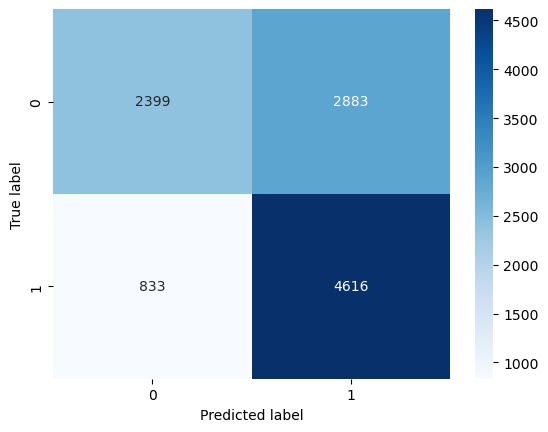

In [140]:
# Compute values for confusion matrix
cm = confusion_matrix(encoded_y_test, y_pred, labels=lr_model.classes_)

# Create display of confusion matrix
cm_display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=lr_model.classes_)

# Plot confusion matrix 
# Display plot
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted label")
plt.ylabel("True label")

In [143]:
# Create a classification report
print(classification_report(encoded_y_test, y_pred, target_names=["not verified", "verified"]))

              precision    recall  f1-score   support

not verified       0.74      0.45      0.56      5282
    verified       0.62      0.85      0.71      5449

    accuracy                           0.65     10731
   macro avg       0.68      0.65      0.64     10731
weighted avg       0.68      0.65      0.64     10731



### Interpret model coefficients

In [145]:
# Get the feature names from the model and the model coefficients (which represent log-odds ratios)
# Place into a DataFrame for readability
pd.DataFrame(data={"Feature Name":lr_model.feature_names_in_, "Model Coefficient":lr_model.coef_[0]})


,Feature Name,Model Coefficient
0,video_duration_sec,8.339653e-03
1,video_view_count,-2.539701e-06
2,video_share_count,4.169901e-06
3,video_comment_count,3.202783e-05
4,claim_status_opinion,3.682328e-04
5,author_ban_status_banned,-1.629099e-05
6,author_ban_status_under review,-7.665654e-07


### Conclusion

1. What are the key takeaways from this project?

2. What results can be presented from this project?

1= The model predicts verified status with about 65% accuracy, finding most verified accounts with recall 0.85 but often mislabeling unverified ones as verified.

2= The confusion matrix, the classification report, and the model coefficients.